# Projet oiseaux · 01 · Exploration et baseline

**But :** reconnaître l'espèce d'un oiseau sur une photo, parmi **525 espèces**.

Ce notebook couvre les étapes 1 et 2 (voir `EXPLICATIONS.md`) :
1. **Explorer** : compter, regarder, vérifier les images et les labels.
2. **Baseline** : le score d'une méthode « bête », le point de comparaison de tout le reste.

Les images ont été extraites des fichiers parquet par `scripts/prepare_data.py` (étape 0) dans `data/train`, `data/val` et `data/test`.

In [1]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

ROOT = Path(".")
meta = pd.read_csv(ROOT / "metadata.csv")
CLASSES = json.loads((ROOT / "classes.json").read_text(encoding="utf-8"))
print(len(meta), "images,", len(CLASSES), "espèces")
meta.head()

89885 images, 525 espèces


,largeur,hauteur,chemin,label,espece,partition,octets,sha1
0,224,224,data/train/ABBOTTS BABBLER/000001.jpg,0,ABBOTTS BABBLER,train,25074,2369d29636cdf61f9cf16bbd152149b53a159292
1,224,224,data/train/ABBOTTS BABBLER/000002.jpg,0,ABBOTTS BABBLER,train,26037,f19b0925a845a962cc67dae8a600c56d1a61d8a2
2,224,224,data/train/ABBOTTS BABBLER/000003.jpg,0,ABBOTTS BABBLER,train,26646,751b1b4a34f82ba56ae348a526c0d6d65a022ffe
3,224,224,data/train/ABBOTTS BABBLER/000004.jpg,0,ABBOTTS BABBLER,train,23848,a6a1b08978f49145f0ac825c5e5ff87e6c6ae8aa
4,224,224,data/train/ABBOTTS BABBLER/000005.jpg,0,ABBOTTS BABBLER,train,24018,66574c621fd455cd18c52cf95aa44ee805922325


## 1. Combien d'images dans chaque tas ?

Rappel : **train** pour apprendre, **val** pour choisir, **test** pour le score final (consulté une seule fois, à la toute fin).

In [2]:
counts = meta["partition"].value_counts().reindex(["train", "val", "test"])
pd.DataFrame({"images": counts, "%": (100 * counts / counts.sum()).round(1)})

,images,%
partition,,
train,84635,94.2
val,2625,2.9
test,2625,2.9


### Les trois tas contiennent-ils les mêmes 525 espèces ?

Si une espèce manquait dans un tas, le modèle ne pourrait jamais la réussir là, ou on ne pourrait pas la mesurer.

In [3]:
per_split = meta.groupby("partition")["label"].nunique()
print(per_split.to_string())
same = (set(meta.loc[meta.partition == "train", "label"])
        == set(meta.loc[meta.partition == "val", "label"])
        == set(meta.loc[meta.partition == "test", "label"]))
print("Mêmes espèces dans les trois tas :", same)

partition
test     525
train    525
val      525
Mêmes espèces dans les trois tas : True


### Un défaut trouvé dans le dataset

En préparant les données, on a découvert que le fichier d'origine déclare **526 noms d'espèces au lieu de 525**. La même espèce y figure deux fois, avec un espace en plus dans l'un des noms :

| Numéro d'origine | Nom | Utilisé par |
|---|---|---|
| 380 | `PARAKETT  AUKLET` (deux espaces) | train (155 images) et test (5) |
| 381 | `PARAKETT AUKLET` (un espace) | validation (5) |

Sans correction, le modèle apprendrait cette espèce sous le numéro 380 et ne pourrait **jamais** réussir les 5 images de validation, étiquetées 381. `prepare_data.py` fusionne donc les deux noms et renumérote les espèces de 0 à 524. C'est exactement le genre d'erreur de label dont parle la slide 78.

## 2. Le train est-il équilibré ?

Un modèle a tendance à favoriser les espèces qu'il a vues le plus souvent. On regarde combien d'images chaque espèce a dans le train.

count    525.0
mean     161.2
std       20.6
min      130.0
25%      150.0
50%      158.0
75%      170.0
max      263.0

Écart max / min : 2.0 fois


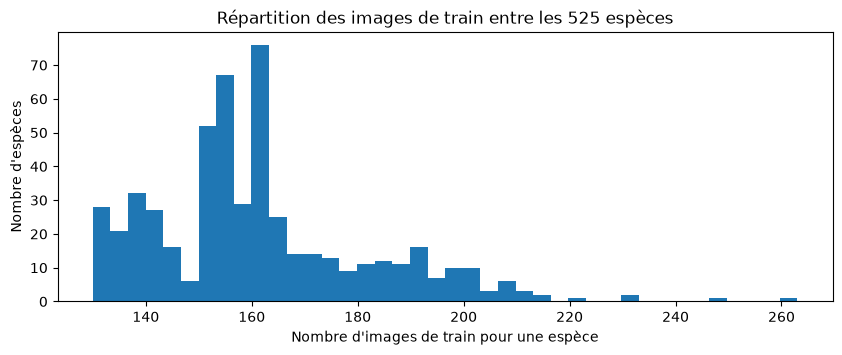

In [4]:
train_counts = meta[meta.partition == "train"]["espece"].value_counts()
print(train_counts.describe().round(1).to_string())
print(f"\nÉcart max / min : {train_counts.max() / train_counts.min():.1f} fois")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(train_counts, bins=40, color="tab:blue")
ax.set_xlabel("Nombre d'images de train pour une espèce")
ax.set_ylabel("Nombre d'espèces")
ax.set_title("Répartition des images de train entre les 525 espèces")
plt.show()

In [5]:
print("Les 5 espèces les MOINS représentées :")
print(train_counts.tail(5).to_string())
print("\nLes 5 espèces les PLUS représentées :")
print(train_counts.head(5).to_string())
print("\nImages par espèce en val :", meta[meta.partition == "val"]["espece"].value_counts().unique())
print("Images par espèce en test :", meta[meta.partition == "test"]["espece"].value_counts().unique())

Les 5 espèces les MOINS représentées :
espece
EURASIAN GOLDEN ORIOLE     130
NORTHERN RED BISHOP        130
PATAGONIAN SIERRA FINCH    130
RED TAILED THRUSH          130
SNOWY PLOVER               130

Les 5 espèces les PLUS représentées :
espece
RUFOUS TREPE             263
HOUSE FINCH              248
D-ARNAUDS BARBET         233
OVENBIRD                 233
ASIAN GREEN BEE EATER    220

Images par espèce en val : [5]
Images par espèce en test : [5]


## 3. Les images sont-elles toutes au même format ?

`prepare_data.py` a noté la largeur et la hauteur de **chaque** image dans `metadata.csv`.

In [6]:
meta["taille"] = meta["largeur"].astype(str) + "x" + meta["hauteur"].astype(str)
odd = meta[meta["taille"] != "224x224"]
print(f"{len(odd)} images sur {len(meta)} ne font pas 224x224")
print(odd["partition"].value_counts().to_string())
print("\nEspèces concernées :")
print(odd["espece"].value_counts().to_string())
print("\nToutes les images de PLUSH CRESTED JAY :",
      len(odd[odd.espece == "PLUSH CRESTED JAY"]), "sur",
      len(meta[meta.espece == "PLUSH CRESTED JAY"]))

211 images sur 89885 ne font pas 224x224
partition
train    201
val        5
test       5

Espèces concernées :
espece
PLUSH CRESTED JAY    210
LOGGERHEAD SHRIKE      1

Toutes les images de PLUSH CRESTED JAY : 210 sur 210


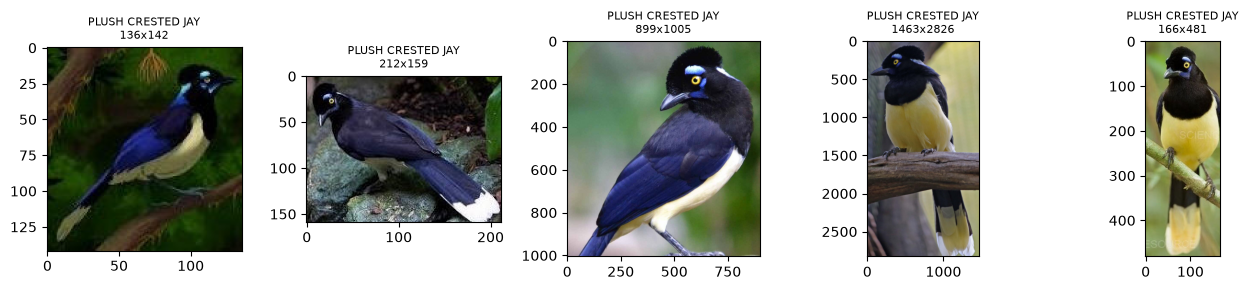

In [7]:
# Des exemples de ces images, avec leur taille d'origine
ex = odd.sample(5, random_state=0)
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for ax, (_, r) in zip(axes, ex.iterrows()):
    ax.imshow(Image.open(ROOT / r.chemin))
    ax.set_title(f"{r.espece}\n{r.taille}", fontsize=8)
plt.tight_layout()
plt.show()

**Lecture :** presque toutes les images font 224 × 224, sauf celles d'**une seule espèce**, PLUSH CRESTED JAY, qui ont toutes une autre taille (et une autre forme).

C'est un **faux indice** possible (slide 77, « le décor peut devenir un faux indice ») : si on donnait les images au modèle à leur taille d'origine, il pourrait reconnaître cette espèce à la forme de l'image, sans regarder l'oiseau. Il faut donc **redimensionner toutes les images en 224 × 224** au chargement (`transforms.Resize`), pour que la taille ne donne aucune information. On vérifiera dans l'analyse des erreurs que cette espèce n'est pas reconnue « trop facilement ».

Toutes les images sont en `RGB` (3 canaux) : pas d'image en noir et blanc à convertir.

## 4. Regarder les images

On ne fait pas confiance à des données qu'on n'a pas regardées. D'abord une image de 15 espèces au hasard.

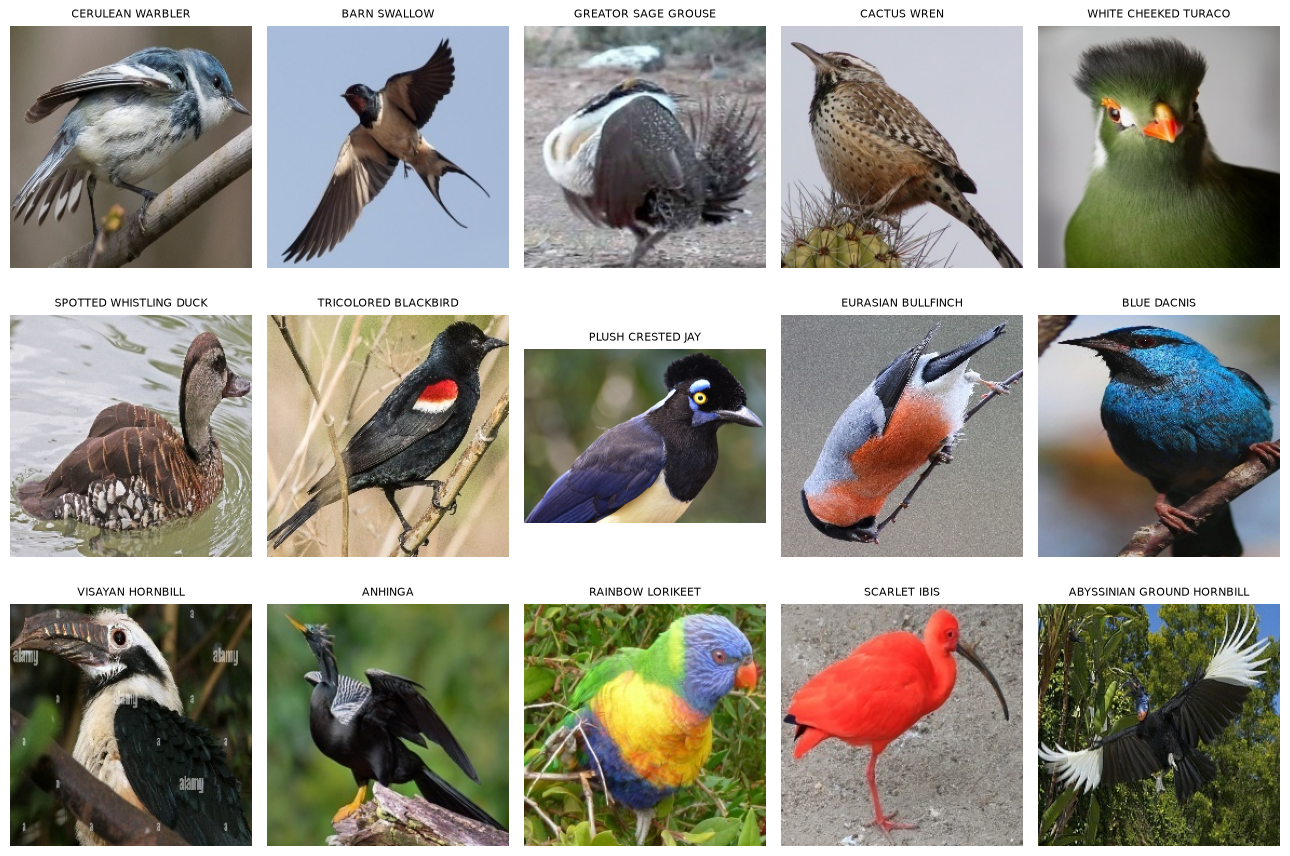

In [8]:
def show(paths, titles, ncols=5, size=2.6):
    nrows = (len(paths) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.15))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, p, t in zip(np.ravel(axes), paths, titles):
        ax.imshow(Image.open(ROOT / p))
        ax.set_title(t, fontsize=8)
    plt.tight_layout()
    plt.show()

random.seed(1)
species = random.sample(CLASSES, 15)
rows = [meta[(meta.partition == "train") & (meta.espece == s)].iloc[0] for s in species]
show([r.chemin for r in rows], [r.espece for r in rows])

**Lecture :** des oiseaux grands, centrés, nets, sur des fonds variés. Attention à un détail : certaines photos portent un **filigrane** (le mot « alamy », une banque d'images, sur le calao VISAYAN HORNBILL par exemple). Si une espèce a souvent ce filigrane et pas les autres, le modèle pourrait s'en servir comme indice. À surveiller dans l'analyse des erreurs.

Puis plusieurs photos d'**une même espèce** : on voit la variété (pose, fond, lumière) que le modèle devra comprendre.

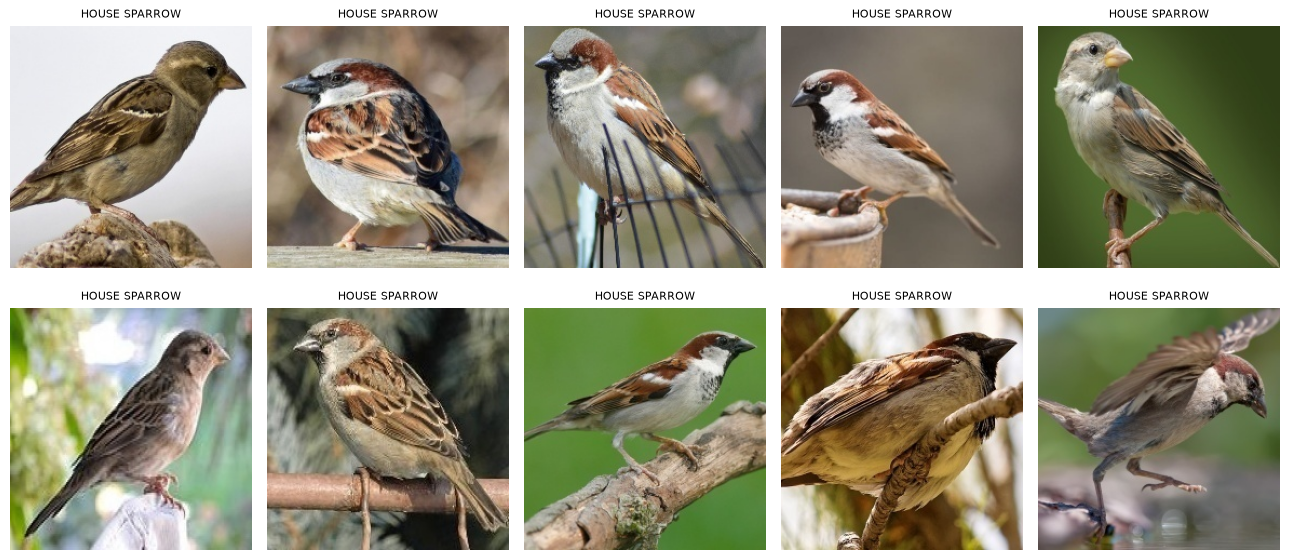

In [9]:
sp = "HOUSE SPARROW"
paths = meta[(meta.partition == "train") & (meta.espece == sp)].sample(10, random_state=0)["chemin"]
show(list(paths), [sp] * 10)

Et des espèces **qui se ressemblent** : c'est ce qui rend la tâche difficile (classification *fine*).

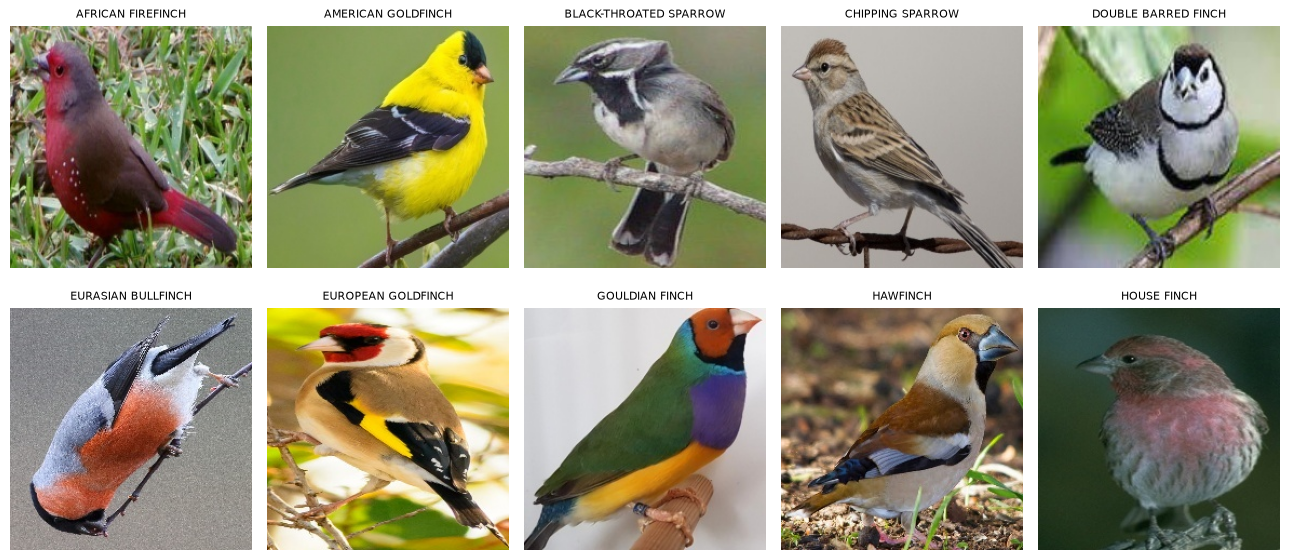

In [10]:
lookalikes = [c for c in CLASSES if "SPARROW" in c or "FINCH" in c][:10]
rows = [meta[(meta.partition == "train") & (meta.espece == s)].iloc[0] for s in lookalikes]
show([r.chemin for r in rows], [r.espece for r in rows])

## 5. Des doublons exacts entre les tas ?

Si une même photo est à la fois dans le train et dans le test, le modèle peut la « reconnaître » juste parce qu'il l'a déjà vue : le score serait gonflé.

`prepare_data.py` a calculé une empreinte (`sha1`) de chaque fichier : deux fichiers identiques octet par octet ont la même empreinte. Ici on ne trouve que les copies **exactes** ; les photos presque identiques (recadrées, recompressées) seront cherchées plus tard avec les embeddings.

In [11]:
dup = meta[meta.duplicated("sha1", keep=False)]
print(len(dup), "fichiers ont au moins une copie exacte")
cross = dup.groupby("sha1")["partition"].agg(lambda s: "+".join(sorted(set(s))))
print(cross.value_counts().to_string() if len(cross) else "aucun")

0 fichiers ont au moins une copie exacte
aucun


## 6. Charger les images avec `ImageFolder` (slide 81)

`ImageFolder` devine l'espèce d'une image grâce au nom de son dossier, et numérote les espèces **par ordre alphabétique des dossiers**. On vérifie que cette numérotation est la même que celle du dataset d'origine, et la même dans les trois tas.

In [12]:
tf = transforms.Compose([
    transforms.Resize((224, 224)),   # toutes les images à la même taille (voir section 3)
    transforms.ToTensor(),           # [0, 255] -> [0, 1], format [C, H, W]
])
train_ds = ImageFolder(ROOT / "data/train", transform=tf)
val_ds = ImageFolder(ROOT / "data/val", transform=tf)
test_ds = ImageFolder(ROOT / "data/test", transform=tf)

assert train_ds.class_to_idx == val_ds.class_to_idx == test_ds.class_to_idx
same_order = train_ds.classes == CLASSES
print("Mêmes numéros dans les 3 tas : True")
print("Même ordre que le dataset d'origine :", same_order)
print(len(train_ds), len(val_ds), len(test_ds))

Mêmes numéros dans les 3 tas : True
Même ordre que le dataset d'origine : True
84635 2625 2625


### Vérifier un batch

Format attendu : `[N, C, H, W]` = `[64, 3, 224, 224]`, des valeurs entre 0 et 1, et des labels entiers de 0 à 524.

In [13]:
loader = DataLoader(train_ds, batch_size=64, shuffle=True)
xb, yb = next(iter(loader))
print(xb.shape, xb.dtype, round(xb.min().item(), 3), round(xb.max().item(), 3))
print(yb.shape, yb.dtype, yb.min().item(), yb.max().item())

torch.Size([64, 3, 224, 224]) torch.float32 0.0 1.0
torch.Size([64]) torch.int64 3 523


## 7. La baseline : toujours répondre l'espèce la plus fréquente

C'est la méthode la plus simple possible. Tout vrai modèle doit faire **beaucoup** mieux ; s'il fait à peu près pareil, c'est qu'il y a un bug.

On la mesure sur la **validation** (le test reste fermé jusqu'à la fin).

In [14]:
train_labels = meta.loc[meta.partition == "train", "label"].to_numpy()
val_labels = meta.loc[meta.partition == "val", "label"].to_numpy()

majority = np.bincount(train_labels).argmax()
acc_majority = (val_labels == majority).mean()

# Variante : répondre au hasard, avec les proportions du train
rng = np.random.default_rng(0)
guess = rng.choice(train_labels, size=len(val_labels))
acc_random = (val_labels == guess).mean()

print(f"Espèce la plus fréquente du train : {CLASSES[majority]}")
print(f"Baseline 'classe majoritaire' : {acc_majority:.2%} sur la validation")
print(f"Baseline 'hasard'             : {acc_random:.2%} sur la validation")
print(f"Pour comparaison, 1/525       : {1/525:.2%}")

Espèce la plus fréquente du train : RUFOUS TREPE
Baseline 'classe majoritaire' : 0.19% sur la validation
Baseline 'hasard'             : 0.15% sur la validation
Pour comparaison, 1/525       : 0.19%


## Ce qu'il faut retenir

- **Les tas** : 84 635 images de train (94,2 %), 2 625 de validation et 2 625 de test (2,9 % chacun, exactement 5 par espèce). Les 525 espèces sont présentes dans les trois.
- **Un défaut de labels corrigé** : PARAKETT AUKLET avait deux numéros (526 noms pour 525 espèces). Sans la fusion, 5 images de validation étaient impossibles à réussir.
- **Le train est un peu déséquilibré** : de 130 à 263 images par espèce (2 fois plus), 161 en moyenne. C'est modéré ; on surveillera quand même si les espèces rares sont moins bien reconnues.
- **Le format** : toutes les images sont en couleur, en 224 × 224 sauf 211, dont les 210 images de PLUSH CRESTED JAY. On redimensionne tout en 224 × 224 pour supprimer ce faux indice.
- **Des filigranes** sur certaines photos : un autre faux indice possible, à surveiller.
- **Aucun doublon exact** entre fichiers. Les quasi-doublons (même photo recadrée ou recompressée) seront cherchés plus tard avec les embeddings.
- **La baseline** : 0,19 % sur la validation en répondant toujours l'espèce la plus fréquente (RUFOUS TREPE), autant que le hasard (1/525). C'est le score à battre.

**Suite :** `02_petit_cnn.ipynb`, le petit CNN fait maison (étape 3).